# Промежуточная аттестация №2
Кручинин С.В.

Работа продолжает исследование из аттестации №1: база **biblioteka** (PostgreSQL, localhost), предметная область — библиотека.

Задача — бинарная **классификация просрочки** выдачи. Данные делю 60% / 20% / 20%: обучение, проверка качества и отдельная часть под «слепой» прогноз, когда таргет не используется совсем.

## 1. Данные из базы biblioteka

In [1]:
import psycopg
import pandas as pd

conn = psycopg.connect(host='localhost', port=5432, dbname='biblioteka',
                       user='postgres', password='123')
df = pd.read_sql('SELECT * FROM v_priznaki_prosrochki ORDER BY vydacha_id', conn)
conn.close()

df['sred_ocenka_knigi'] = df['sred_ocenka_knigi'].astype(float)
df['sred_ocenka_knigi'] = df['sred_ocenka_knigi'].fillna(df['sred_ocenka_knigi'].mean())
df.to_csv('3_vygruzka/priznaki.csv', index=False, encoding='utf-8-sig')
print('строк', len(df), '| просрочек', int(df['prosrochka'].sum()))
df.head(3)

строк 96 | просрочек 27


C:\Users\Папа\AppData\Local\Temp\ipykernel_7348\3706706100.py:6: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql('SELECT * FROM v_priznaki_prosrochki ORDER BY vydacha_id', conn)


,vydacha_id,chitatel_id,fio,vozrast,lyubimyy_zhanr,lyubimaya_tema,kniga_id,nazvanie,avtor,zhanr,...,srok_sdachi,data_vozvrata,otsenka,srok_dney,prosrochka,na_rukah,zhanr_sovpal,tema_sovpala,skok_brali,sred_ocenka_knigi
0,1,1,Соколова Анна Сергеевна,22,фантастика,космос,21,Пикник на обочине,Аркадий и Борис Стругацкие,фантастика,...,2026-06-28,2026-06-28,5.0,14,0,0,1,1,4,4.500000
1,2,1,Соколова Анна Сергеевна,22,фантастика,космос,1,Война и мир,Лев Толстой,роман,...,2026-07-16,2026-07-21,3.0,14,1,0,0,0,9,3.888889
2,3,1,Соколова Анна Сергеевна,22,фантастика,космос,4,Идиот,Фёдор Достоевский,роман,...,2026-08-03,2026-08-08,2.0,14,1,0,0,0,10,3.600000


Выгрузка из базы на 3 ноября: **96 выдач, 27 с просрочкой**. В сентябре, когда я делал аттестацию 1, просрочек было 16 — тогда часть книг ещё была на руках, и срок по ним не вышел. Теперь они тоже попадают в просрочку, поэтому данных о классе 1 стало больше. Файл сохранён в `3_vygruzka/priznaki.csv`.

## 2. Задача машинного обучения и признаки

Классификация: **вернёт ли читатель книгу с просрочкой** (target = `prosrochka`, 1/0).

Практический смысл: библиотекарь в день выдачи видит, какие выдачи с высокой вероятностью затянутся, и заранее напоминает именно этим читателям про срок.

Признаки: возраст читателя, срок книги, сколько раз книгу брали, средняя оценка книги, совпадение темы с любимой, а также история читателя — сколько раз он уже опаздывал раньше.

In [2]:
df = df.sort_values(['chitatel_id', 'data_vydachi']).reset_index(drop=True)
# сколько раз читатель уже просрочил ДО этой выдачи
df['opozdal_ranee'] = df.groupby('chitatel_id')['prosrochka'].cumsum() - df['prosrochka']

FULL = ['vozrast', 'srok_dney', 'skok_brali', 'sred_ocenka_knigi',
        'zhanr_sovpal', 'tema_sovpala', 'na_rukah', 'opozdal_ranee']
SHORT = ['vozrast', 'srok_dney', 'skok_brali', 'sred_ocenka_knigi',
         'tema_sovpala', 'opozdal_ranee']
print(df.groupby('prosrochka')[FULL].mean().round(2))

            vozrast  srok_dney  skok_brali  sred_ocenka_knigi  zhanr_sovpal  \
prosrochka                                                                    
0             30.01       14.0        5.59               3.81          0.28   
1             24.33       14.0        5.93               3.76          0.19   

            tema_sovpala  na_rukah  opozdal_ranee  
prosrochka                                         
0                   0.23      0.00           0.23  
1                   0.15      0.56           0.56  


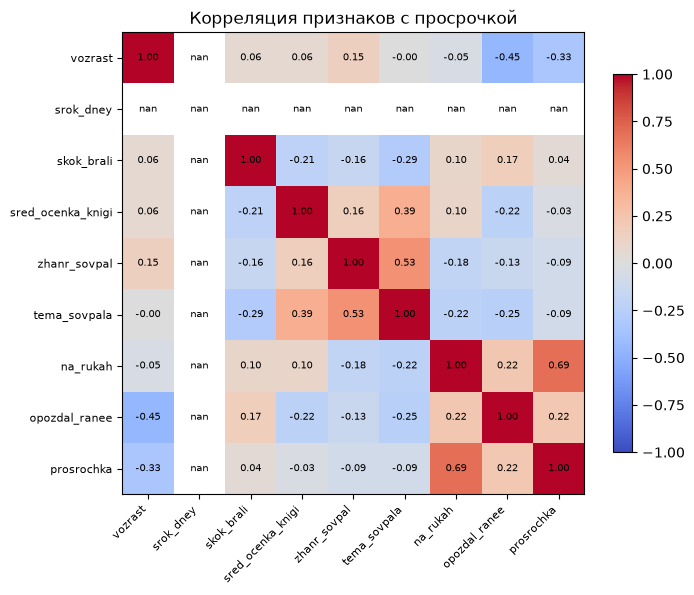

In [3]:
import matplotlib.pyplot as plt
import numpy as np
fig, ax = plt.subplots(figsize=(7.2, 6))
num = df[FULL + ['prosrochka']].corr()
im = ax.imshow(num, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(num.columns)), num.columns, rotation=45, ha='right', fontsize=8)
ax.set_yticks(range(len(num.columns)), num.columns, fontsize=8)
for i in range(len(num)):
    for j in range(len(num)):
        ax.text(j, i, f'{num.iloc[i, j]:.2f}', ha='center', va='center', fontsize=7)
fig.colorbar(im, shrink=0.8)
ax.set_title('Корреляция признаков с просрочкой')
fig.tight_layout()
fig.savefig('4_grafiki/a2_heat_corr.png', dpi=130)
plt.show()

## 3. Разделение 60% / 20% / 20%

In [4]:
from sklearn.model_selection import train_test_split

X_tr, X_tmp, y_tr, y_tmp, idx_tr, idx_tmp = train_test_split(
    df[FULL], df['prosrochka'], df.index,
    test_size=0.4, stratify=df['prosrochka'], random_state=42)
X_ev, X_bl, y_ev, y_bl, idx_ev, idx_bl = train_test_split(
    X_tmp, y_tmp, idx_tmp, test_size=0.5, stratify=y_tmp, random_state=42)
print('обучение', len(X_tr), '| оценка', len(X_ev), '| слепой прогноз', len(X_bl))

обучение 57 | оценка 19 | слепой прогноз 20


Обучающая выборка — 60%. Тестовые 40% делю пополам: первые 20% (`test_eval`) — знаю таргет, на них считаю качество; вторые 20% (`test_blind`) — таргет не смотрю, модель работает как в реальной эксплуатации.

## 4. Модели и оценка на первых 20% теста

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def models():
    return {
        'Логистическая регрессия': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42)),
        'kNN (k=5)': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
        'SVM': make_pipeline(StandardScaler(), SVC(random_state=42)),
        'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42),
        'Градиентный бустинг': HistGradientBoostingClassifier(random_state=42),
    }

rows = []
for feat_name, feats in (('полный', FULL), ('сокращённый', SHORT)):
    for name, m in models().items():
        m.fit(X_tr[feats], y_tr)
        p = m.predict(X_ev[feats])
        rows.append({'набор': feat_name, 'модель': name,
                     'accuracy': round(accuracy_score(y_ev, p), 3),
                     'precision': round(precision_score(y_ev, p, zero_division=0), 3),
                     'recall': round(recall_score(y_ev, p), 3),
                     'f1': round(f1_score(y_ev, p), 3)})
metriki = pd.DataFrame(rows)
metriki.to_csv('3_vygruzka/metriki_modeli.csv', index=False, encoding='utf-8-sig')
metriki

,набор,модель,accuracy,precision,recall,f1
0,полный,Логистическая регрессия,0.789,0.667,0.4,0.500
1,полный,kNN (k=5),0.789,0.667,0.4,0.500
2,полный,SVM,0.842,1.000,0.4,0.571
3,полный,Random Forest,0.842,0.667,0.8,0.727
4,полный,Градиентный бустинг,0.684,0.400,0.4,0.400
5,сокращённый,Логистическая регрессия,0.895,0.800,0.8,0.800
6,сокращённый,kNN (k=5),0.632,0.400,0.8,0.533
7,сокращённый,SVM,0.789,0.667,0.4,0.500
8,сокращённый,Random Forest,0.684,0.429,0.6,0.500
9,сокращённый,Градиентный бустинг,0.684,0.400,0.4,0.400


## 5. Выбор модели и набора переменных

лучшая связка: Логистическая регрессия | набор: сокращённый | f1 = 0.8


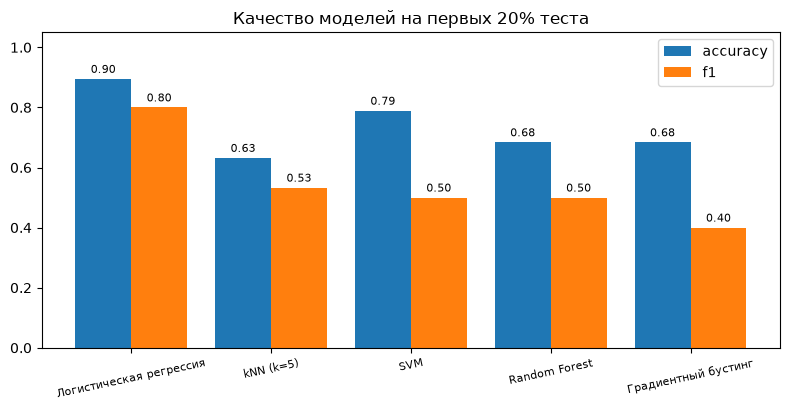

In [6]:
import matplotlib.pyplot as plt
import numpy as np

best = metriki.sort_values('f1', ascending=False).iloc[0]
print('лучшая связка:', best['модель'], '| набор:', best['набор'], '| f1 =', best['f1'])

top = metriki[metriki['набор'] == best['набор']].sort_values('f1', ascending=False)
fig, ax = plt.subplots(figsize=(8, 4.2))
x = np.arange(len(top))
ax.bar(x - 0.2, top['accuracy'], width=0.4, label='accuracy')
ax.bar(x + 0.2, top['f1'], width=0.4, label='f1')
ax.set_xticks(x, top['модель'], rotation=12, fontsize=8)
ax.set_ylim(0, 1.05)
for xi, (a, f) in enumerate(zip(top['accuracy'], top['f1'])):
    ax.text(xi - 0.2, a + 0.02, f'{a:.2f}', ha='center', fontsize=8)
    ax.text(xi + 0.2, f + 0.02, f'{f:.2f}', ha='center', fontsize=8)
ax.legend()
ax.set_title('Качество моделей на первых 20% теста')
fig.tight_layout()
fig.savefig('4_grafiki/a2_bar_modeli.png', dpi=130)
plt.show()

Матрица ошибок и важность признаков лучшей модели:

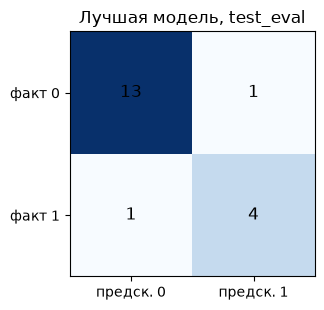

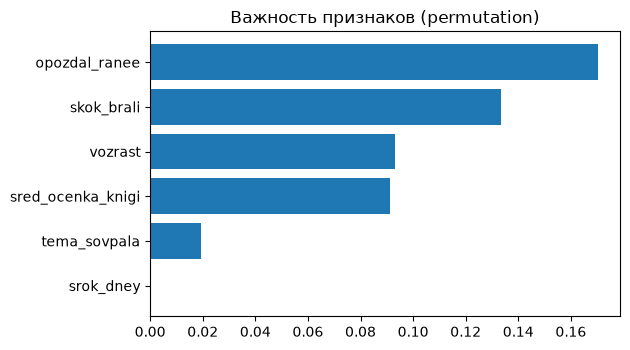

In [7]:
from sklearn.metrics import confusion_matrix
from sklearn.inspection import permutation_importance

feats = SHORT if best['набор'] == 'сокращённый' else FULL
best_model = models()[best['модель']]
best_model.fit(X_tr[feats], y_tr)
p_best = best_model.predict(X_ev[feats])

cm = confusion_matrix(y_ev, p_best)
fig, ax = plt.subplots(figsize=(3.6, 3.2))
ax.imshow(cm, cmap='Blues')
ax.set_xticks([0, 1], ['предск. 0', 'предск. 1'])
ax.set_yticks([0, 1], ['факт 0', 'факт 1'])
for i in range(2):
    for j in range(2):
        ax.text(j, i, str(cm[i, j]), ha='center', va='center', fontsize=12)
ax.set_title('Лучшая модель, test_eval')
fig.tight_layout()
fig.savefig('4_grafiki/a2_conf_matrix.png', dpi=130)
plt.show()

pi = permutation_importance(best_model, X_ev[feats], y_ev, n_repeats=30, random_state=42)
order = np.argsort(pi.importances_mean)
fig, ax = plt.subplots(figsize=(6.4, 3.6))
ax.barh([feats[i] for i in order], pi.importances_mean[order])
ax.set_title('Важность признаков (permutation)')
fig.tight_layout()
fig.savefig('4_grafiki/a2_imp_features.png', dpi=130)
plt.show()

## 6. Слепой прогноз на вторых 20% (таргет скрыт)

строк: 20 | спрогнозировано просрочек: 2


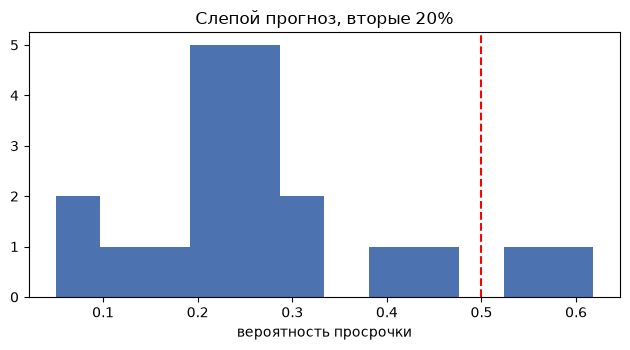

,vydacha_id,prognoz_prosrochka,verojatnost
73,64,1,0.618
91,82,0,0.266
35,92,0,0.400
21,91,0,0.202
52,44,0,0.319
38,33,0,0.269
72,63,1,0.542
53,45,0,0.468


In [8]:
blind = df.loc[idx_bl].copy()
proba = best_model.predict_proba(blind[feats])[:, 1]
pred = best_model.predict(blind[feats])

prognoz = pd.DataFrame({'vydacha_id': blind['vydacha_id'],
                        'prognoz_prosrochka': pred,
                        'verojatnost': np.round(proba, 3)})
prognoz.to_csv('3_vygruzka/prognoz.csv', index=False, encoding='utf-8-sig')
print('строк:', len(prognoz), '| спрогнозировано просрочек:', int(pred.sum()))

fig, ax = plt.subplots(figsize=(6.4, 3.6))
ax.hist(proba, bins=12, color='#4c72b0')
ax.axvline(0.5, color='red', linestyle='--')
ax.set_xlabel('вероятность просрочки')
ax.set_title('Слепой прогноз, вторые 20%')
fig.tight_layout()
fig.savefig('4_grafiki/a2_prognoz_hist.png', dpi=130)
plt.show()
prognoz.head(8)

## 7. Рекомендации для пользователей анализа

Кому полезна модель и что с прогнозом делать:

1. **Библиотекарь на выдаче** — если модель дала вероятность выше 0.5, напомнить читателю про срок возврата в день выдачи и предложить короткий срок для толстых книг.
2. **Автонапоминания** — за два дня до срока письмо/смс только тем, у кого прогноз 1: не спамим всех, напоминания точечные.
3. **Комплектование фонда** — по важности признаков видно, что влияет на просрочку; книги с большим сроком и низкой популярностью брать в фонд аккуратнее.
4. **Мониторинг** — раз в месяц сравнивать фактические просрочки с прогнозом: если модель начала ошибаться, признак «история опозданий» устарел и нужен дообучающий прогон.

## 8. Нейросеть (MLP) на тех же данных

In [9]:
from sklearn.neural_network import MLPClassifier

mlp = make_pipeline(StandardScaler(),
                    MLPClassifier(hidden_layer_sizes=(32, 16), max_iter=3000, random_state=42))
mlp.fit(X_tr[feats], y_tr)
p_mlp = mlp.predict(X_ev[feats])
print('MLP  accuracy', round(accuracy_score(y_ev, p_mlp), 3),
      '| precision', round(precision_score(y_ev, p_mlp, zero_division=0), 3),
      '| recall', round(recall_score(y_ev, p_mlp), 3),
      '| f1', round(f1_score(y_ev, p_mlp), 3))
print('лучшая классическая:', best['модель'], 'f1 =', best['f1'])

MLP  accuracy 0.579 | precision 0.333 | recall 0.6 | f1 0.429
лучшая классическая: Логистическая регрессия f1 = 0.8


### Задача для нейросети другой архитектуры

Отдельно предложил бы задачу **классификации жанра книги по обложке**: свёрточная сеть (CNN, как ResNet/VGG из уроков 65–66) смотрит на изображение обложки и определяет жанр. Разметка есть — жанр у каждой книги в базе, обложки можно собрать по ISBN. Учебный прототип на CIFAR10 уже разбирали в Colab, для реальных данных подойдёт transfer learning с готовым backbone.

Ещё вариант (с вебинара) — определить тональность отзывов читателей рекуррентной сетью и использовать это как признак в модели оттока.